# AVIPE signal chain: the math

Each step below is one block of the chain, written as the math it does:

microphone → sum of 3 → DC removal → 512-sample frames → FFT → frame to MCU → Hamming window + magnitude

Change anything in the **Inputs** cell and run all cells to see what it does at each step.

## 0. Inputs

In [1]:
# ======================= INPUTS =======================
# ---- rates ----
MIC_RATE   = 46_875         # mic samples per second, Hz

# ---- microphone ----
MIC_BITS   = 18             # bits per mic sample, two's complement

# ---- test signal, in mic LSBs: DC_OFFSET + one tone + noise ----
TONE_HZ     = 32 * 15625 / 512               # bin 32 = 976.6 Hz
TONE_AMP    = 8000
DC_OFFSET   = -3000
NOISE_LSB   = 2                              # rms white noise
SEED        = 1

# ---- sum of 3 ----
SUM_N      = 3              # mic samples added per output sample

# ---- DC removal ----
AVERAGE_SHIFT = 10          # running average weight a = 2**-AVERAGE_SHIFT
OUT_BITS      = 16          # output sample width; values past it are clipped

# ---- frames ----
FRAME_N    = 512            # samples per frame = FFT points
HOP        = 312            # new samples between frames

# ---- FFT ----
FFT_OUT_BITS = 16           # bits for re and im of each bin; the whole frame shares one power-of-2 scale

# ---- output ----
N_FRAMES       = 12         # frames to compute
FRAME_TO_PLOT  = 12         # which frame to send through the FFT (1 = first)
SEND_BINS      = 256        # bins sent to the MCU
# ======================================================

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({'figure.figsize': (11, 3.6), 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

FS        = MIC_RATE / SUM_N                       # output sample rate
SUM_BITS  = MIC_BITS + int(np.ceil(np.log2(SUM_N)))
A         = 2.0 ** -AVERAGE_SHIFT                  # running average weight
BIN_HZ    = FS / FRAME_N
FIRST_END = -(-FRAME_N // HOP) * HOP               # samples needed for frame 1
N_OUT     = FIRST_END + HOP * (N_FRAMES - 1)
N_MIC     = N_OUT * SUM_N

def quantize(x, bits):
    # round to an integer and clip to a signed `bits`-bit range
    top = 2 ** (bits - 1)
    return np.clip(np.rint(x), -top, top - 1).astype(np.int64)

def changes(rows, cols=('before', 'after')):
    # small table of what changed in this step
    display(pd.DataFrame(rows, columns=['', *cols]).set_index(''))

changes([
    ('output rate fs', f'{FS/1e3:g} kHz'),
    ('sum width', f'{SUM_BITS} bits'),
    ('DC cutoff', f'{A*FS/(2*np.pi):.2f} Hz'),
    ('frame every', f'{HOP/FS*1e3:.2f} ms'),
    ('bin width', f'{BIN_HZ:.2f} Hz'),
], cols=('derived',))


,derived
,
output rate fs,15.625 kHz
sum width,20 bits
DC cutoff,2.43 Hz
frame every,19.97 ms
bin width,30.52 Hz


## 1. Microphone
The test signal, rounded to integers and clipped to `MIC_BITS` bits:

$$x[m] = \mathrm{clip}\big(\mathrm{round}(s(m / f_{mic}))\big)$$

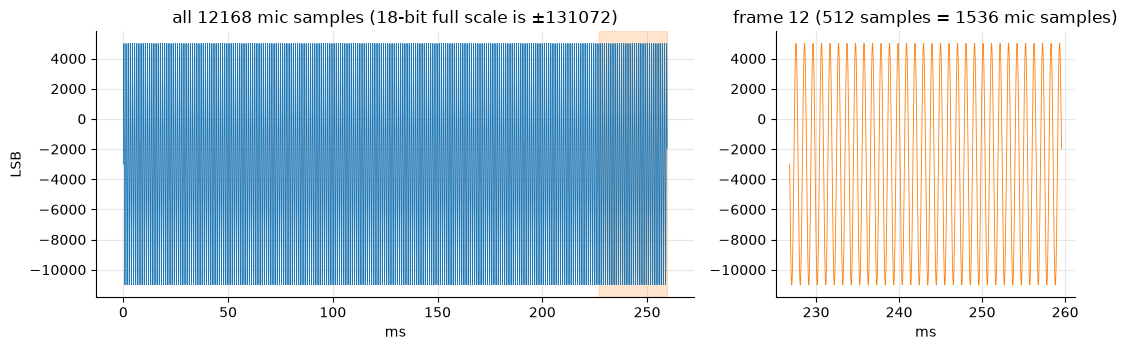

,value
,
rate,46.875 kHz
width,18 bits
peak,11006 LSB
mean (DC),-2990


In [3]:
def make_signal(n):
    t = np.arange(n) / MIC_RATE
    x = DC_OFFSET + TONE_AMP * np.sin(2 * np.pi * TONE_HZ * t)
    x += np.random.default_rng(SEED).normal(0, NOISE_LSB, n)
    return quantize(x, MIC_BITS)

x = make_signal(N_MIC)

fig, ax = plt.subplots(1, 2, gridspec_kw={'width_ratios': [2, 1]})
t_ms = np.arange(N_MIC) / MIC_RATE * 1e3
ax[0].plot(t_ms, x, lw=0.6)
lim = ax[0].get_ylim()                       # scale to the data; full-scale lines only show if reached
for s in (1, -1):
    ax[0].axhline(s * 2 ** (MIC_BITS - 1), color='k', ls='--', lw=1)
ax[0].set(title=f'all {N_MIC} mic samples ({MIC_BITS}-bit full scale is ±{2**(MIC_BITS-1)})', xlabel='ms', ylabel='LSB', ylim=lim)
k0 = min(FRAME_TO_PLOT, N_FRAMES) - 1       # same frame the FFT uses
s0 = (FIRST_END - FRAME_N + HOP * k0) * SUM_N
z = slice(s0, s0 + FRAME_N * SUM_N)
ax[0].axvspan(t_ms[z][0], t_ms[z][-1], color='C1', alpha=0.2)
ax[1].plot(t_ms[z], x[z], lw=0.6, color='C1')
ax[1].set(title=f'frame {k0 + 1} ({FRAME_N} samples = {FRAME_N * SUM_N} mic samples)', xlabel='ms')
plt.tight_layout(); plt.show()

peak = max(np.abs(x).max(), 1)
changes([('rate', f'{MIC_RATE/1e3:g} kHz'), ('width', f'{MIC_BITS} bits'),
         ('peak', f'{peak} LSB'), ('mean (DC)', f'{x.mean():.0f}')], cols=('value',))

## 2. Sum of 3
Adds each group of 3 mic samples, so the rate drops by 3:

$$y[n] = x[3n] + x[3n+1] + x[3n+2]$$

That is also a low-pass filter. A sine at frequency $f$ comes out with gain

$$G(f) = \frac{\sin(3\theta)}{\sin\theta}, \qquad \theta = \frac{\pi f}{f_{mic}}$$

which is 3 at DC and 2 (−3.5 dB) at the top frequency $f_s/2$.

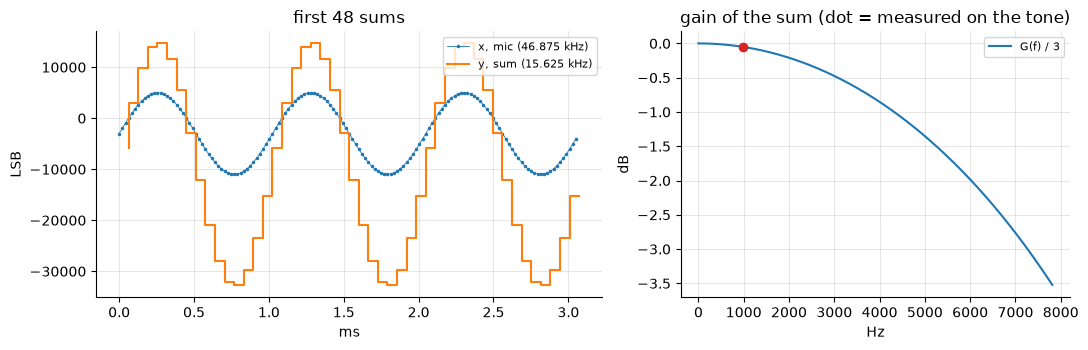

,before,after
,,
rate,46.875 kHz,15.625 kHz
width,18 bits,20 bits
peak,11006,32667
mean (DC),-2990,-8970
tone amplitude,7992,"23840 (gain 2.9829, G = 2.9829)"


In [4]:
y = x[:N_OUT * SUM_N].reshape(N_OUT, SUM_N).sum(axis=1)

def sum_gain(f):
    th = np.pi * np.asarray(f, float) / MIC_RATE
    return np.where(th == 0, SUM_N, np.sin(SUM_N * th) / np.where(th == 0, 1, np.sin(th)))

def tone_size(v, f, rate):
    # amplitude of the sine at f in v, by correlating with exp(-j 2 pi f t)
    n = np.arange(len(v))
    return 2 * np.abs(np.mean(v * np.exp(-2j * np.pi * f * n / rate)))

fig, ax = plt.subplots(1, 2, gridspec_kw={'width_ratios': [1.3, 1]})
ax[0].plot(np.arange(3 * 48) / MIC_RATE * 1e3, x[:3 * 48], '.-', ms=3, lw=0.6, label=f'x, mic ({MIC_RATE/1e3:g} kHz)')
ax[0].step((np.arange(48) + 1) * SUM_N / MIC_RATE * 1e3, y[:48], where='pre', color='C1', label=f'y, sum ({FS/1e3:g} kHz)')
ax[0].set(title='first 48 sums', xlabel='ms', ylabel='LSB'); ax[0].legend(fontsize=8)
f = np.linspace(0, FS / 2, 400)
ax[1].plot(f, 20 * np.log10(np.abs(sum_gain(f)) / SUM_N), label='G(f) / 3')
meas = tone_size(y, TONE_HZ, FS) / tone_size(x, TONE_HZ, MIC_RATE)
ax[1].plot(TONE_HZ, 20 * np.log10(meas / SUM_N), 'o', color='C3')
ax[1].set(title='gain of the sum (dot = measured on the tone)', xlabel='Hz', ylabel='dB'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
changes([
    ('rate', f'{MIC_RATE/1e3:g} kHz', f'{FS/1e3:g} kHz'),
    ('width', f'{MIC_BITS} bits', f'{SUM_BITS} bits'),
    ('peak', f'{np.abs(x).max()}', f'{np.abs(y).max()}'),
    ('mean (DC)', f'{x.mean():.0f}', f'{y.mean():.0f}'),
    ('tone amplitude', f'{tone_size(x, TONE_HZ, MIC_RATE):.0f}', f'{tone_size(y, TONE_HZ, FS):.0f}  (gain {meas:.4f}, G = {float(sum_gain(TONE_HZ)):.4f})'),
])


## 3. DC removal
Subtracts a slow running average $\mu$, with weight $a = 2^{-\text{AVERAGE\_SHIFT}}$:

$$\mu[n+1] = \mu[n] + a\,(y[n] - \mu[n]), \qquad d[n] = y[n] - \mu[n]$$

$$p[n] = \mathrm{clip}_{\text{OUT\_BITS}}\big(\mathrm{round}(d[n])\big)$$

As a filter this is a high-pass:

$$H(z) = \frac{1 - z^{-1}}{1 - (1-a)\,z^{-1}}$$

It has a −3 dB cutoff of about $a f_s / 2\pi$. A constant $D$ at the input decays at the output as $D\,(1-a)^n$.

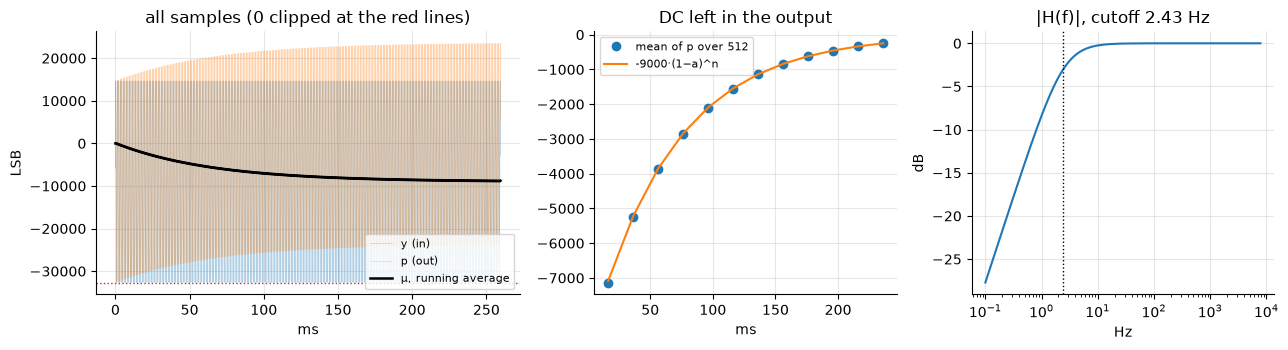

,before,after
,,
width,20 bits,16 bits
peak,32667,32621
"mean, last 512",-9000,-223.6
clipped,-,0


In [5]:
mu = np.zeros(N_OUT)
for n in range(N_OUT - 1):
    mu[n + 1] = mu[n] + A * (y[n] - mu[n])
d = y - mu
p = quantize(d, OUT_BITS)
clipped = int(np.sum(np.abs(d) > 2 ** (OUT_BITS - 1) - 1))

t = np.arange(N_OUT) / FS * 1e3
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={'width_ratios': [1.4, 1, 1]})
ax[0].plot(t, y, lw=0.4, alpha=0.35, color='C0', label='y (in)')
ax[0].plot(t, p, lw=0.4, alpha=0.35, color='C1', label='p (out)')
ax[0].plot(t, mu, 'k', lw=1.8, label='μ, running average')
lim = ax[0].get_ylim()                       # scale to the data; clip lines only show if reached
for s in (1, -1):
    ax[0].axhline(s * 2 ** (OUT_BITS - 1), color='C3', ls=':', lw=1)
ax[0].set_ylim(lim)
ax[0].set(title=f'all samples ({clipped} clipped at the red lines)', xlabel='ms', ylabel='LSB'); ax[0].legend(fontsize=8, loc='lower right')
# DC left in each frame-length window vs D (1-a)^n
starts = np.arange(0, N_OUT - FRAME_N + 1, HOP)
D = SUM_N * DC_OFFSET
ax[1].plot((starts + FRAME_N / 2) / FS * 1e3, [p[s:s + FRAME_N].mean() for s in starts], 'o', label=f'mean of p over {FRAME_N}')
ax[1].plot((starts + FRAME_N / 2) / FS * 1e3, [np.mean(D * (1 - A) ** np.arange(s, s + FRAME_N)) for s in starts],
           label=f'{D}·(1−a)^n')
ax[1].set(title='DC left in the output', xlabel='ms'); ax[1].legend(fontsize=8)
fr = np.logspace(-1, np.log10(FS / 2), 400)
zi = np.exp(-2j * np.pi * fr / FS)
H = (1 - zi) / (1 - (1 - A) * zi)
ax[2].semilogx(fr, 20 * np.log10(np.abs(H)))
ax[2].axvline(A * FS / (2 * np.pi), color='k', ls=':', lw=1)
ax[2].set(title=f'|H(f)|, cutoff {A*FS/(2*np.pi):.2f} Hz', xlabel='Hz', ylabel='dB')
plt.tight_layout(); plt.show()
last = slice(-FRAME_N, None)
changes([
    ('width', f'{SUM_BITS} bits', f'{OUT_BITS} bits'),
    ('peak', f'{np.abs(y).max()}', f'{np.abs(p).max()}'),
    (f'mean, last {FRAME_N}', f'{y[last].mean():.0f}', f'{p[last].mean():.1f}'),
    ('clipped', '-', f'{clipped}'),
])

## 4. Frames
Frame $k$ is the latest `FRAME_N` output samples each time `HOP` new ones have arrived, once there are enough for a full frame:

$$\text{frame}_k[i] = p[s_k + i], \quad i = 0 \dots \text{FRAME\_N}-1, \quad s_k = s_1 + \text{HOP}\,(k-1)$$

Neighbouring frames overlap by `FRAME_N − HOP` samples.

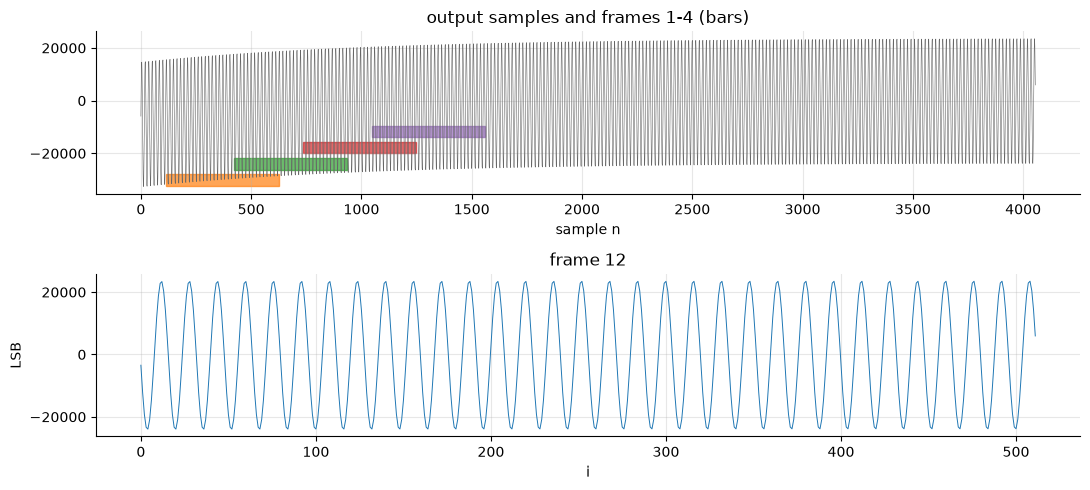

,before,after
,,
unit,1 sample,512 samples
rate,15.625 kHz,50.1 frames/s
overlap,-,200 samples
first frame ready,-,32.8 ms


In [6]:
frame_starts = FIRST_END - FRAME_N + HOP * np.arange(N_FRAMES)
frames = [p[s:s + FRAME_N] for s in frame_starts]
frame_table = pd.DataFrame({'frame': np.arange(1, N_FRAMES + 1), 'first sample': frame_starts,
                            'last sample': frame_starts + FRAME_N - 1,
                            'ready at ms': (frame_starts + FRAME_N) / FS * 1e3}).set_index('frame')

fig, ax = plt.subplots(2, 1, figsize=(11, 5))
ax[0].plot(np.arange(N_OUT), p, lw=0.4, color='0.4')
for k in range(min(4, N_FRAMES)):
    s = frame_starts[k]
    ax[0].axvspan(s, s + FRAME_N, ymin=0.05 + 0.1 * k, ymax=0.12 + 0.1 * k, color=f'C{k+1}', alpha=0.7)
ax[0].set(title='output samples and frames 1-4 (bars)', xlabel='sample n')
kp = min(FRAME_TO_PLOT, N_FRAMES)
ax[1].plot(frames[kp - 1], lw=0.7)
ax[1].set(title=f'frame {kp}', xlabel='i', ylabel='LSB')
plt.tight_layout(); plt.show()
changes([
    ('unit', '1 sample', f'{FRAME_N} samples'),
    ('rate', f'{FS/1e3:g} kHz', f'{FS/HOP:.1f} frames/s'),
    ('overlap', '-', f'{FRAME_N - HOP} samples'),
    ('first frame ready', '-', f'{(FRAME_N)/FS*1e3:.1f} ms' if HOP <= FRAME_N else f'{FIRST_END/FS*1e3:.1f} ms'),
])

## 5. FFT
The discrete Fourier transform of the frame:

$$X[k] = \sum_{i=0}^{N-1} \text{frame}[i]\, e^{-j 2\pi k i / N}$$

Bin $k$ is at $k \cdot f_s / N$, and a sine of amplitude $A$ that lands exactly on a bin gives $|X[k]| = A N / 2$.

The result is then stored in `FFT_OUT_BITS` bits. The whole frame shares one scale $2^{e}$, the smallest that makes the largest part fit, so $X \approx X_q \cdot 2^{e}$.

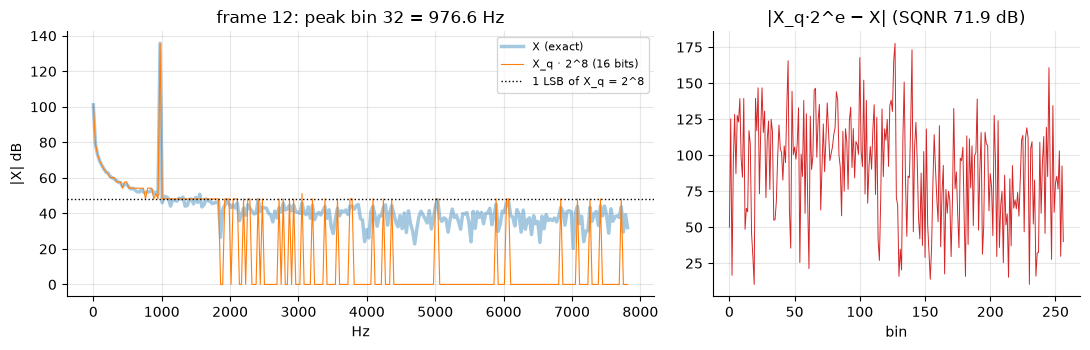

,before,after
,,
width,16 bits,"16+16 bits, scale 2^8"
peak,23945 (time),"23876 (bin 32, 976.6 Hz)"
expected peak,-,8000·2.9829 = 23863
SQNR,-,71.9 dB


In [7]:
frame = frames[kp - 1].astype(float)
X = np.fft.fft(frame)
top = 2 ** (FFT_OUT_BITS - 1) - 1
biggest = max(np.abs(X.real).max(), np.abs(X.imag).max())
e = max(0, int(np.ceil(np.log2(biggest / top)))) if biggest > 0 else 0
Xq_re, Xq_im = quantize(X.real / 2 ** e, FFT_OUT_BITS), quantize(X.imag / 2 ** e, FFT_OUT_BITS)
Xq = (Xq_re + 1j * Xq_im) * 2.0 ** e
err = Xq - X
sqnr = 10 * np.log10(np.sum(np.abs(X) ** 2) / max(np.sum(np.abs(err) ** 2), 1e-30))
bins = np.arange(FRAME_N // 2 + 1)
amp = 2 * np.abs(X[:FRAME_N // 2 + 1]) / FRAME_N
peak = 1 + int(np.argmax(amp[1:FRAME_N // 2]))

fig, ax = plt.subplots(1, 2, gridspec_kw={'width_ratios': [1.6, 1]})
db = lambda v: 20 * np.log10(np.maximum(np.abs(v), 1))
ax[0].plot(bins * BIN_HZ, db(X[bins]), lw=2.5, alpha=0.4, label='X (exact)')
ax[0].plot(bins * BIN_HZ, db(Xq[bins]), lw=0.8, label=f'X_q · 2^{e} ({FFT_OUT_BITS} bits)')
ax[0].axhline(20 * np.log10(2 ** e), color='k', ls=':', lw=1, label=f'1 LSB of X_q = 2^{e}')
ax[0].set(title=f'frame {kp}: peak bin {peak} = {peak*BIN_HZ:.1f} Hz', xlabel='Hz', ylabel='|X| dB')
ax[0].legend(fontsize=8)
ax[1].plot(bins, np.abs(err[bins]), lw=0.7, color='C3')
ax[1].set(title=f'|X_q·2^e − X| (SQNR {sqnr:.1f} dB)', xlabel='bin')
plt.tight_layout(); plt.show()

k = int(round(TONE_HZ / BIN_HZ))
g = float(sum_gain(TONE_HZ))
changes([
    ('width', f'{OUT_BITS} bits', f'{FFT_OUT_BITS}+{FFT_OUT_BITS} bits, scale 2^{e}'),
    ('peak', f'{np.abs(frame).max():.0f} (time)', f'{amp[peak]:.0f} (bin {peak}, {peak*BIN_HZ:.1f} Hz)'),
    ('expected peak', '-', f'{TONE_AMP}·{g:.4f} = {TONE_AMP*g:.0f}'),
    ('SQNR', '-', f'{sqnr:.1f} dB'),
])


## 6. Frame to the MCU
For a real input, $X[N-k] = \overline{X[k]}$, so the top half repeats the bottom half and only `SEND_BINS` bins need to be sent. Each bin is re then im, followed by the exponent $e$.

In [8]:
assert np.allclose(X[1:FRAME_N // 2], np.conj(X[:FRAME_N // 2:-1]))
part_bytes = (FFT_OUT_BITS + 7) // 8
frame_bytes = 4 + 2 * part_bytes * SEND_BINS
print(f'X[N-k] = conj(X[k]) ✓   {SEND_BINS} bins x {2*FFT_OUT_BITS} bits + 32-bit header = {frame_bytes} bytes '
      f'= {8*frame_bytes*FS/HOP/1e3:.0f} kbit/s at {FS/HOP:.1f} frames/s')

X[N-k] = conj(X[k]) ✓   256 bins x 32 bits + 32-bit header = 1028 bytes = 412 kbit/s at 50.1 frames/s


## 7. Hamming window and magnitude (MCU)
Multiplying the frame by the Hamming window $w[i] = 0.54 - 0.46\cos(2\pi i/N)$ before the FFT is the same as mixing each bin with its neighbours after it:

$$X_w[k] = 0.54\,X[k] - 0.23\,(X[k-1] + X[k+1])$$

The cell checks that the two match, then finds the magnitude of bins 1 to `SEND_BINS − 2` and the largest.

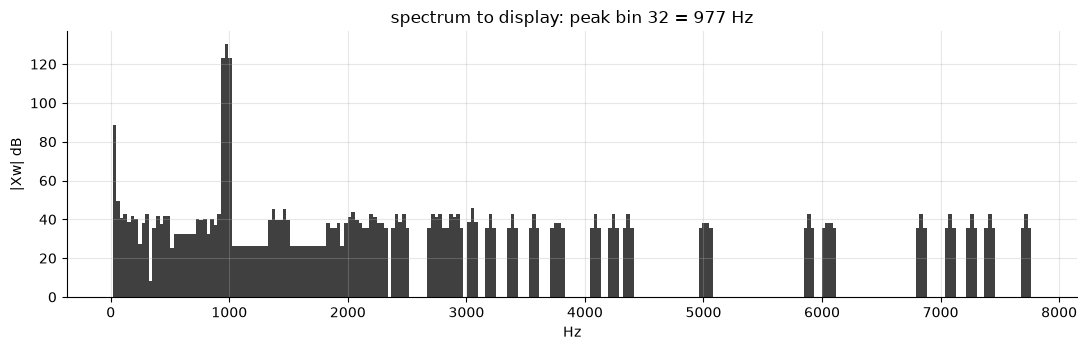

largest difference between window-after and window-before: 9.31e-10 ✓


In [9]:
kk = np.arange(1, SEND_BINS - 1)
Xr = (Xq_re[:SEND_BINS] + 1j * Xq_im[:SEND_BINS]) * 2.0 ** e
Xw = 0.54 * Xr[kk] - 0.23 * (Xr[kk - 1] + Xr[kk + 1])
w = 0.54 - 0.46 * np.cos(2 * np.pi * np.arange(FRAME_N) / FRAME_N)
Xw_direct = np.fft.fft(frame * w)[kk]
match = np.max(np.abs(0.54 * X[kk] - 0.23 * (X[kk - 1] + X[kk + 1]) - Xw_direct))
mag = np.abs(Xw)
pk = kk[np.argmax(mag)]

fig, ax = plt.subplots()
ax.bar(kk * BIN_HZ, 20 * np.log10(np.maximum(mag, 1)), width=BIN_HZ, color='0.25')
ax.set(title=f'spectrum to display: peak bin {pk} = {pk*BIN_HZ:.0f} Hz', xlabel='Hz', ylabel='|Xw| dB')
plt.tight_layout(); plt.show()
print(f'largest difference between window-after and window-before: {match:.2e} ✓')

## 8. Summary

In [10]:
display(pd.DataFrame([
    ('microphone', f'{MIC_BITS}', f'{MIC_RATE/1e3:g} kHz', f'peak {np.abs(x).max()} LSB'),
    ('sum of 3', f'{SUM_BITS}', f'{FS/1e3:g} kHz', f'peak {np.abs(y).max()}'),
    ('DC removal', f'{OUT_BITS}', f'{FS/1e3:g} kHz', f'{clipped} clipped'),
    ('frames', f'{FRAME_N} x {OUT_BITS}', f'{FS/HOP:.1f} frames/s', f'{N_FRAMES} frames'),
    ('FFT', f'{FFT_OUT_BITS}+{FFT_OUT_BITS}, scale 2^{e}', f'{FS/HOP:.1f} frames/s', f'SQNR {sqnr:.1f} dB'),
    ('to MCU', '8', f'{frame_bytes} bytes/frame', f'{8*frame_bytes*FS/HOP/1e3:.0f} kbit/s'),
    ('display', '-', '-', f'peak {pk*BIN_HZ:.0f} Hz'),
], columns=['step', 'bits', 'rate', 'result']).set_index('step'))

,bits,rate,result
step,,,
microphone,18,46.875 kHz,peak 11006 LSB
sum of 3,20,15.625 kHz,peak 32667
DC removal,16,15.625 kHz,0 clipped
frames,512 x 16,50.1 frames/s,12 frames
FFT,"16+16, scale 2^8",50.1 frames/s,SQNR 71.9 dB
to MCU,8,1028 bytes/frame,412 kbit/s
display,-,-,peak 977 Hz
